# Step 17 — 2D Nonlinear Shallow Water: a Wind-Driven Double Gyre

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/sesmax/blob/main/docs/notebooks/step17_shallow_water_2d.ipynb)

*Part of the rotating shallow-water series; moved from somax's tutorial series.*

A wind that blows west in the tropics and at high latitudes, and east in between, sets an ocean basin turning: one gyre each side of the middle latitude. Because the Coriolis parameter grows with latitude, the return flow of both gyres leans on the western side, in a fast and narrow boundary current. This notebook spins that flow up from rest with the nonlinear shallow-water equations.

**What you'll learn:**

1. How to run [`NonlinearShallowWater2D`](xref:api#sesmax_ocean.swm.NonlinearShallowWater2D) between walls, on a $\beta$-plane, under a wind
2. How wide the western boundary current is, and how to check that the grid resolves it
3. How the interior compares with Sverdrup balance
4. How to differentiate a run with respect to the wind and the viscosity

## Setup

On Colab, install `sesmax-ocean`; locally, with the repository's environment, this does nothing.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    repository = "git+https://github.com/jejjohnson/sesmax@main#subdirectory=packages/"
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            f"sesmax-core @ {repository}sesmax-core",
            f"sesmax-ocean @ {repository}sesmax-ocean",
        ],
        check=True,
    )

## The PDE

The rotating shallow-water equations for the layer thickness $h$ and the velocity $(u, v)$, in vector-invariant form:

$$
\frac{\partial h}{\partial t} + \frac{\partial (h u)}{\partial x} + \frac{\partial (h v)}{\partial y} = 0
$$

$$
\frac{\partial u}{\partial t} - q h v = -\frac{\partial B}{\partial x} - \tau_0 \cos\left(\frac{2 \pi y}{L_y}\right) + \nu \nabla^2 u - \kappa u
$$

$$
\frac{\partial v}{\partial t} + q h u = -\frac{\partial B}{\partial y} + \nu \nabla^2 v - \kappa v
$$

with the potential vorticity $q = (\zeta + f) / h$, the relative vorticity $\zeta = \partial v / \partial x - \partial u / \partial y$, the Coriolis parameter $f = f_0 + \beta (y - L_y / 2)$ and the Bernoulli function $B = \frac{1}{2} (u^2 + v^2) + g h$. The walls are closed and free slip.

Away from the walls and from fast currents, the curl of the wind balances the advection of planetary vorticity. This is Sverdrup balance:

$$
\beta v_S = -\frac{\partial}{\partial y}\left[-\tau_0 \cos\left(\frac{2 \pi y}{L_y}\right)\right] = -\frac{2 \pi \tau_0}{L_y} \sin\left(\frac{2 \pi y}{L_y}\right)
$$

It moves water south in the southern half of the basin and north in the northern half, so a boundary current has to bring it back. Friction sets its width: the Munk width $\delta_M = (\nu / \beta)^{1/3}$ for viscosity, and the Stommel width $\delta_S = \kappa / \beta$ for drag.

### Symbols

The page is dimensional, in SI units.

| Symbol | Meaning | Shape |
| --- | --- | --- |
| $(x, y)$ | spatial coordinates (m) | $\mathbb{R}^2$ |
| $t$ | time (s) | $\mathbb{R}$ |
| $h(x, y, t)$ | layer thickness (m) | $\mathbb{R}_{>0}$ |
| $u(x, y, t)$, $v(x, y, t)$ | velocity components (m/s) | $\mathbb{R}$ |
| $\eta = h - H_0$ | height of the sea surface above rest (m) | $\mathbb{R}$ |
| $q$, $\zeta$, $B$ | potential vorticity (1/(m s)), relative vorticity (1/s) and Bernoulli function (m²/s²) | $\mathbb{R}$ |
| $g$, $H_0$, $f_0$ | gravity (m/s²), depth at rest (m) and Coriolis parameter at mid-basin (1/s) | $\mathbb{R}_{>0}$ |
| $\beta$ | meridional gradient of $f$ (1/(m s)) | $\mathbb{R}_{>0}$ |
| $\tau_0$ | wind acceleration (m/s²) | $\mathbb{R}_{>0}$ |
| $\nu$, $\kappa$ | viscosity (m²/s) and bottom drag (1/s) | $\mathbb{R}_{>0}$ |
| $v_S(y)$ | Sverdrup velocity (m/s) | $\mathbb{R}$ |
| $\delta_M$, $\delta_S$ | Munk and Stommel widths (m) | $\mathbb{R}_{>0}$ |
| $L_x$, $L_y$ | domain lengths (m) | $\mathbb{R}_{>0}$ |
| $N_{\Omega_x,x}$, $N_{\Omega_x,y}$, $N_T$ | number of interior cells along $x$ and $y$, and of saved snapshots | count |
| $\Delta x$, $\Delta t$ | grid spacing (m) and time step (s) | $\mathbb{R}_{>0}$ |

In [2]:
import diffrax as dfx
import einx
import equinox as eqx
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

from sesmax_ocean.resolution import check_munk_width
from sesmax_ocean.swm import NonlinearShallowWater2D, NonlinearSW2DState

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic(
        "watermark", "-v -m -p jax,equinox,diffrax,sesmax_core,sesmax_ocean"
    )
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.10.0

jax         : 0.12.0.1
equinox     : 0.13.8
diffrax     : 0.7.2
sesmax_core : 0.3.1
sesmax_ocean: 0.0.0

Compiler    : Clang 21.1.4 
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



## 1. Create the model

A square basin of 1000 km. The wind is weak, so the boundary current stays laminar. The viscosity is large enough for the grid to resolve that current, and [`check_munk_width`](xref:api#sesmax_ocean.resolution.check_munk_width) says so: it raises if the grid is coarser than the Munk width, and warns if fewer than four cells span it. The Stommel width is much smaller, so viscosity sets the width here.

In [4]:
# Shapes: N_Ωx,x = N_Ωx,y = 48 interior cells

num_cells = 48
domain_length = 1.0e6
gravity = 9.81
coriolis = 1.0e-4
beta = 1.6e-11
mean_depth = 500.0
viscosity = 1.0e4
drag = 2.0e-7
wind = 2.0e-7

# today (sesmax_ocean)
model = NonlinearShallowWater2D.create(
    nx=num_cells,
    ny=num_cells,
    Lx=domain_length,
    Ly=domain_length,
    g=gravity,
    f0=coriolis,
    beta=beta,
    H0=mean_depth,
    lateral_viscosity=viscosity,
    bottom_drag=drag,
    wind_amplitude=wind,
    wind_profile="doublegyre",
    bc="wall",
)

spacing = model.grid.spacing("x")
# δ_M = (ν / β)^(1/3)
munk_width = (viscosity / beta) ** (1.0 / 3.0)
# δ_S = κ / β
stommel_width = drag / beta
# c = √(g H₀)
phase_speed = jnp.sqrt(gravity * mean_depth)  # → ()
print(f"Grid spacing:  {spacing / 1e3:.1f} km")
print(f"Munk width:    {munk_width / 1e3:.1f} km")
print(f"Stommel width: {stommel_width / 1e3:.1f} km")
print(f"Gravity waves: {float(phase_speed):.0f} m/s")

# today (sesmax_ocean): passes without a word
check_munk_width(None, model)

Grid spacing:  20.8 km
Munk width:    85.5 km
Stommel width: 12.5 km
Gravity waves: 70 m/s


## 2. Forward simulation

From rest, for about 58 days, in steps of a fifth of the time a gravity wave needs to cross a cell.

The integrator fills the ghost cells of every state it evaluates, but not of the states it returns, so we fill them before we compute diagnostics.

In [5]:
# Shapes: N_T = 100 saved snapshots; G = (N_Ωx,y + 2) × (N_Ωx,x + 2) with the ghosts

at_rest = jnp.zeros(model.grid.shape)  # → G
# today (sesmax_ocean)
initial_state = NonlinearSW2DState(h=at_rest + mean_depth, u=at_rest, v=at_rest)

end_time = 5.0e6
# tₖ = k t₁ / (N_T − 1)
save_times = jnp.linspace(0.0, end_time, 100)  # → (N_T,)
# Δt = 0.2 Δx / c
time_step = 0.2 * spacing / phase_speed  # → ()

# today (sesmax_core, diffrax)
solution = model.integrate(  # h, u, v → N_T × G each
    initial_state,
    t0=0.0,
    t1=end_time,
    dt=time_step,
    saveat=dfx.SaveAt(ts=save_times),
    max_steps=200_000,
)
# today (sesmax_ocean): the ghosts of each snapshot, then its diagnostics
states = jax.vmap(model.apply_boundary_conditions)(solution.ys)
diagnostics = jax.vmap(model.diagnose)(states)

mass = diagnostics.mass  # → (N_T,)
largest_u = jnp.max(jnp.abs(states.u[-1]))  # → ()
largest_v = jnp.max(jnp.abs(states.v[-1]))  # → ()
print(f"All finite: {bool(jnp.all(jnp.isfinite(states.h)))}")
print(f"Largest |u|, |v|: {float(largest_u):.2f}, {float(largest_v):.2f} m/s")
print(f"Change of the mass: {float(jnp.max(jnp.abs(mass / mass[0] - 1.0))):.0e}")

All finite: True
Largest |u|, |v|: 0.25, 0.29 m/s


Change of the mass: 1e-07


## 3. The gyres

The surface is low in the gyre that turns anticlockwise, in the north, and high in the one that turns clockwise, in the south. Both are pressed against the western side.

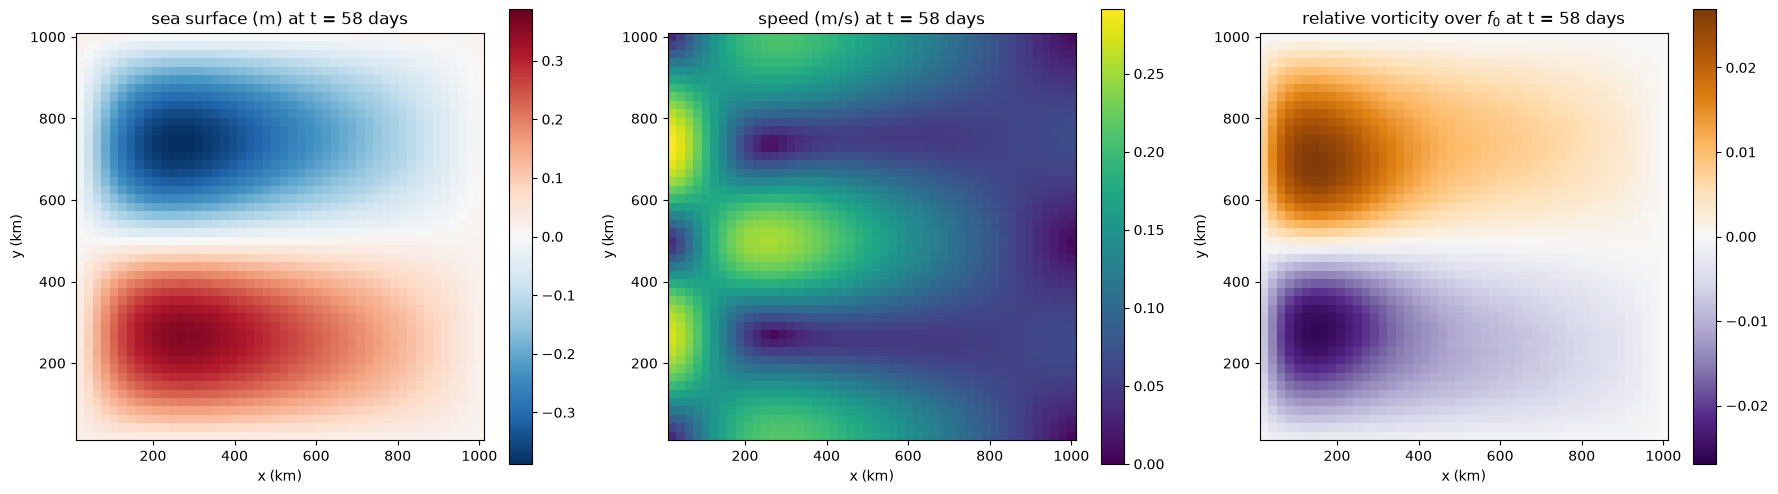

In [6]:
# Shapes: N_Ωx,x = 48 columns; N_Ωx,y = 48 rows

inner = slice(1, -1)
interior = (inner, inner)
# xᵢ = i Δx, yⱼ = j Δy
x_position = jnp.arange(model.grid.Nx) * spacing  # → (N_Ωx,x + 2,)
y_position = jnp.arange(model.grid.Ny) * spacing  # → (N_Ωx,y + 2,)
x_km = x_position[inner] / 1e3
y_km = y_position[inner] / 1e3

# η = h − H₀
surface = states.h[-1] - mean_depth  # → G
# |u| = √(2 KE)
speed = jnp.sqrt(2.0 * diagnostics.kinetic_energy_field[-1])  # → G
vorticity = diagnostics.relative_vorticity[-1]  # → G

panels = [
    (surface[interior], "RdBu_r", "sea surface (m)"),
    (speed[interior], "viridis", "speed (m/s)"),
    (vorticity[interior] / coriolis, "PuOr_r", "relative vorticity over $f_0$"),
]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (field, colours, label) in zip(axes, panels, strict=True):
    largest = float(jnp.max(jnp.abs(field)))
    lowest = 0.0 if colours == "viridis" else -largest
    mesh = ax.pcolormesh(
        x_km, y_km, field, cmap=colours, vmin=lowest, vmax=largest, shading="auto"
    )
    ax.set_title(f"{label} at t = {end_time / 86400.0:.0f} days")
    ax.set_xlabel("x (km)")
    ax.set_ylabel("y (km)")
    ax.set_aspect("equal")
    plt.colorbar(mesh, ax=ax)
plt.tight_layout()
plt.show()

## 4. The boundary current and the interior

A section of $v$ across each gyre, where the wind's curl is strongest, with the Sverdrup velocity of that latitude. On the right, the mean kinetic energy while the gyres spin up.

southern gyre: boundary current +0.27 m/s, eastern half -0.052 m/s, Sverdrup -0.079 m/s
northern gyre: boundary current -0.29 m/s, eastern half +0.053 m/s, Sverdrup +0.079 m/s


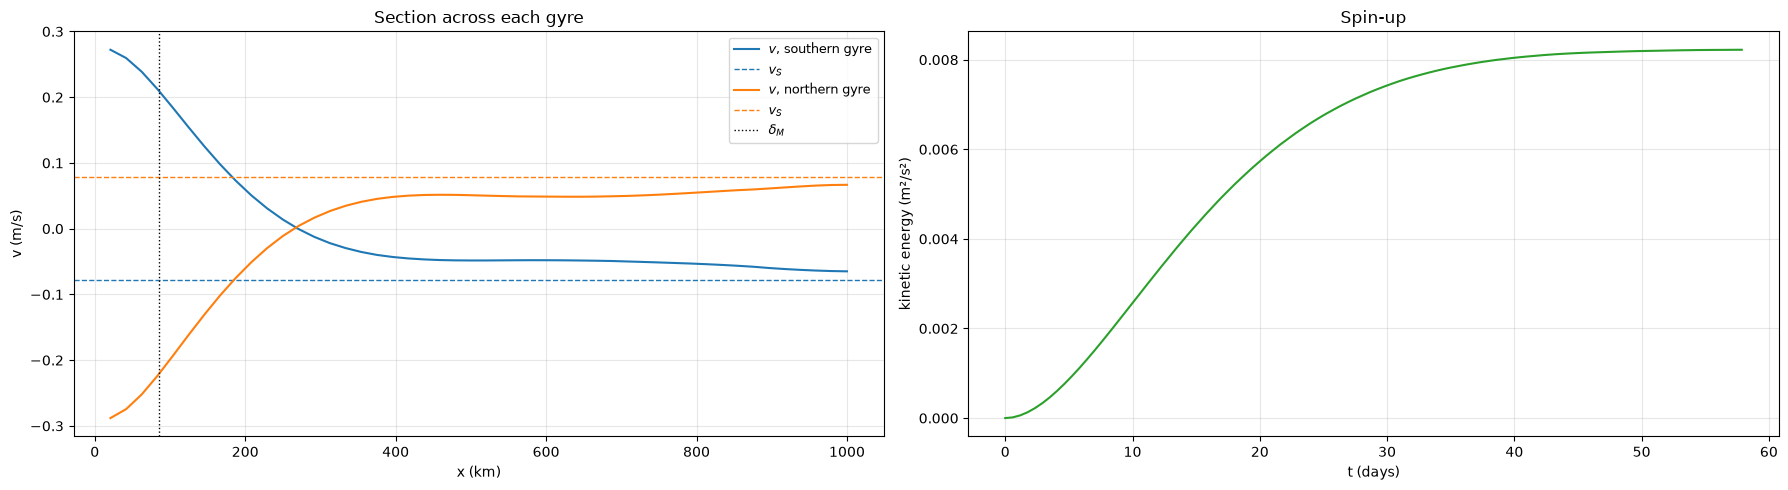

In [7]:
# Shapes: N_Ωx,x = 48 columns; N_T = 100 saved snapshots

fig, axes = plt.subplots(1, 2, figsize=(18, 5))
fractions = {"southern gyre": 0.25, "northern gyre": 0.75}
for index, (name, fraction) in enumerate(fractions.items()):
    row = round(fraction * num_cells)
    section = states.v[-1][row, inner]  # → (N_Ωx,x,)
    # v_S = −(2π τ₀ / (β L_y)) sin(2π y / L_y)
    angle = 2.0 * jnp.pi * y_position[row] / domain_length  # → ()
    sverdrup = -2.0 * jnp.pi * wind / (beta * domain_length) * jnp.sin(angle)  # → ()
    axes[0].plot(x_km, section, color=f"C{index}", label=f"$v$, {name}")
    axes[0].axhline(sverdrup, color=f"C{index}", ls="--", lw=1.0, label="$v_S$")
    # the eastern half of the basin, off both walls
    middle = section[num_cells // 2 : -4]  # → (N_Ωx,x / 2 − 4,)
    mean_middle = einx.mean("[x] ->", middle)  # → ()
    print(
        f"{name}: boundary current {float(section[0]):+.2f} m/s, "
        f"eastern half {float(mean_middle):+.3f} m/s, "
        f"Sverdrup {float(sverdrup):+.3f} m/s"
    )
axes[0].axvline(munk_width / 1e3, color="k", ls=":", lw=1.0, label=r"$\delta_M$")
axes[0].set_xlabel("x (km)")
axes[0].set_ylabel("v (m/s)")
axes[0].set_title("Section across each gyre")
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3)

kinetic = diagnostics.kinetic_energy_field[:, inner, inner]  # → N_T × N_Ωx,y × N_Ωx,x
mean_kinetic = einx.mean("time [y x] -> time", kinetic)  # → (N_T,)
axes[1].plot(save_times / 86400.0, mean_kinetic, color="C2")
axes[1].set_xlabel("t (days)")
axes[1].set_ylabel("kinetic energy (m²/s²)")
axes[1].set_title("Spin-up")
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

The boundary current is fast on the western wall and gone a few Munk widths away from it. In the eastern half of the basin the flow has the sign of Sverdrup balance in both gyres and about two thirds of its size: with a Munk width of a twelfth of the basin, friction is felt everywhere.

## 5. Differentiate the run

A run is a differentiable function of the model's parameters. Here the loss is the mean kinetic energy after a day, and the gradient says what one unit of each parameter is worth; we print it as an elasticity, the relative change of the loss for a relative change of the parameter.

In [8]:
# Shapes: G = (N_Ωx,y + 2) × (N_Ωx,x + 2) with the ghosts

# The gyres as they are after 58 days
spun_up = jax.tree.map(lambda field: field[-1], states)


# today (equinox)
@eqx.filter_value_and_grad
def energy_after_a_day(candidate):
    run = candidate.integrate(spun_up, t0=0.0, t1=86400.0, dt=time_step)
    final = jax.tree.map(lambda field: field[-1], run.ys)
    final = candidate.apply_boundary_conditions(final)
    kinetic = candidate.diagnose(final).kinetic_energy_field
    return einx.mean("[y x] ->", kinetic[interior])


loss, gradient = energy_after_a_day(model)
for name in ("wind_amplitude", "lateral_viscosity", "bottom_drag"):
    # (θ / ℒ) ∂ℒ/∂θ
    value = getattr(model.params, name)  # → ()
    elasticity = value / loss * getattr(gradient.params, name)  # → ()
    print(f"{name:18s} {float(elasticity):+.3f}")

wind_amplitude     +0.134
lateral_viscosity  -0.099
bottom_drag        -0.032


## Summary

| Concept | sesmax API |
| --- | --- |
| Create the model | `NonlinearShallowWater2D.create(nx, ny, Lx, Ly, ..., wind_profile="doublegyre", bc="wall")` |
| Initial state | `NonlinearSW2DState(h=..., u=..., v=...)` |
| Check the grid | `check_munk_width(None, model)` |
| Ghosts of a run's states | `jax.vmap(model.apply_boundary_conditions)(solution.ys)` |
| Diagnostics of a run | `jax.vmap(model.diagnose)(states)` |

- The wind drives two gyres, and the $\beta$-effect presses their return flow against the western wall.
- The width of the boundary current is the larger of the Munk and Stommel widths, and the grid has to resolve it.
- Mass is conserved to rounding, and no flow crosses the walls.